# Cleaning: Part-1

The goal now is to post-process the job descriptions you collected in `HW-3.1-crawl.ipynb`.

In this section you MUST do it manually using traditional data science cleaning and parsing skills, i.e. without use of ANY LLM tools or wrappers. (You will do the LLM version in `HW-3.3-cleaning-2.ipynb`, and compare the two in your EDA.)

The unit of analysis in this case is "job", i.e. one row per unique job posting.

Your task is to write a cleaning script that parses the crawl results and creates a data frame, saved to `data/processed-jobs-1.csv`. This data frame will be used for later EDA.

## Getting started

Some tips for working with the raw crawl files:

* Load every JSON file in `data/` (e.g. with `glob`), and collect the entries of each file's `jobs_results` list. Skip the provided `example-out-...` file, or keep it, but make that choice deliberately.
* Each job has useful semi-structured fields in addition to the free-text `description`, e.g. `title`, `company_name`, `location`, `via` (the posting platform), `detected_extensions` (posting age, schedule type, salary, benefits flags), `job_highlights` (qualifications, responsibilities, benefits), and `job_id`. Field availability varies from job to job, so code defensively (e.g. `.get()`).
* `posted_at` values are relative (e.g. "4 days ago"). To convert them to dates, combine them with the time of the crawl, which is available in each file's `search_metadata` (or in your timestamped filename).
* The same job often appears under several search queries. `job_id`, or a combination of title, company, and location, is a good starting point for deduplication.
* Keep track of which search query each job came from; it is a useful feature in its own right.

## Features to extract

Try to extract as many features as possible. Here are some possible suggestions, which together provide a comprehensive overview for analyzing job postings for trends, patterns, and insights.

You will almost certainly not be able to extract all of these features, but do your best to make the most detailed data set that you can. You can also ADD more features to this list if they come to mind.

- **Job Title**
- **Company Name**
- **Sector/Industry**
- **Location** (City, State, Country)
- **Job Type** (Full-time, Part-time, Contract, Internship)
- **Salary** (Range or Exact)
- **Experience Level** (Entry-level, Mid-level, Senior-level)
- **Education Requirements** (Degree, Major, Certifications)
- **Skills/Technologies Required** (e.g., Python, SQL, Machine Learning, Cloud)
- **Job Responsibilities/Duties**
- **Required Years of Experience**
- **Benefits** (Health insurance, Retirement plans, Paid time off)
- **Remote Work Options** (Remote, Hybrid, On-site)
- **Application Deadline**
- **Job Posting Date**
- **Job Description Length** (Number of words or characters)
- **Keywords/Frequency of Terms**
- **Certifications Required or Preferred** (e.g., AWS Certified, PMP)
- **Team Size** (If mentioned)
- **Company Size** (Small, Medium, Large)
- **Company Reputation/Ranking** (If available)
- **Job Posting Platform** (Where the job was posted, e.g., LinkedIn, Indeed)
- **Company Values or Culture** (Diversity, Innovation, Sustainability)
- **Visa Sponsorship Availability**
- **Interview Process Information** (If mentioned)
- **Expected Start Date**
- **Job Posting Expiry Date**
- **Gender Diversity Language** (If any)
- **Working Hours/Shift Type** (Day shift, Night shift, Flexible hours)
- **Required Language Skills**
- **Job Location Proximity to Major Cities** (If provided)
- **Travel Requirements** (Percentage or Frequency)
- **Team Collaboration Tools Mentioned** (Slack, Zoom, etc.)
- **Reporting Line** (e.g., Reports to Senior Manager)
- **Job Benefits Related to Learning & Development** (e.g., Courses, Training)
- **Company Stock Options** (If offered)
- **Required Soft Skills** (e.g., Communication, Leadership)
- **Company Perks** (Gym membership, Free meals, Company car)
- **Job Posting ID or Reference Number**

## Cleaning checklist

While cleaning, try to address the following as best you can:

- **Missing Data**: Identify missing or null values in features like salary, company name, or location.
- **Duplicates**: Check for duplicate job listings or job descriptions.
- **Inconsistent Formatting**: Ensure consistency in categorical variables (e.g., job titles, location formats).
- **Data Type Validation**: Ensure each feature has the appropriate data type (e.g., salary as numeric, dates as datetime).
- **Outliers**: Detect outliers in salary, years of experience, or job description length.

## Method and scope

This pipeline uses local Python, regular expressions, dictionaries, explicit rules, and pandas. It does not call a language model, a search service, or any other API during cleaning. The unit of analysis is a **unique posting**, with multiple locations and raw occurrences attached to that posting.

The 2024 instructor example is deliberately excluded. All 90 response files from the completed live crawl are read, and original JSON is preserved. A posting retains its source files, search queries, raw IDs, platforms, alternative titles, and locations so every output row can be traced back to its inputs.

| Concern | Decision |
|---|---|
| Duplicates | Link matching job IDs; identical descriptions of at least 40 words from the same company; or matching normalized title/company/location with at least 95% token-sequence similarity. Identical long descriptions across locations become one posting with all locations retained. Distinct descriptions under the same canonical key are retained and flagged. |
| Text and categories | Unicode normalization, HTML entity decoding, whitespace cleanup, standardized state abbreviations, platform labels, and job-type categories. Keep original title, full cleaned description, and raw location. |
| Missing values | Leave unsupported scalars blank/nullable. Empty JSON arrays mean no matching evidence found, not a confirmed absence of a skill or benefit. No salary/experience imputation. |
| Salary source | Prefer detected fields, then extension labels, then benefits highlights, then description. Keep the matched evidence and source. Periods must occur directly with the pay amount or in an explicit preceding pay label. |
| Salary assumptions | Convert hourly ×2,080, daily ×260, weekly ×52, monthly ×12. These are full-time annualized equivalents, not guaranteed earnings. Unmarked currency is assumed USD because searches targeted the U.S.; flag this assumption. Pay of at least 10,000 without a unit is treated as annual and explicitly flagged. Unknown small-amount periods remain missing. |
| Multiple pay bands | Keep the first eligible range in the preferred source, flag multiple ranges, and preserve the source description for review. Geographic bands cannot be assigned reliably to a single location by these rules. |
| Relative dates | Anchor to each saved response's `search_metadata.created_at`, with collection metadata/filename fallback. Mark relative dates as approximate; months/years use calendar offsets, and `30+ days` produces an upper date bound. Never anchor ages to the current execution date. |
| Skills and education | Match explicit terms with boundaries, e.g. Java is distinct from JavaScript and SQL from NoSQL. These are mentions, not proof that every skill/degree is mandatory. Certifications need explicit certification terms. |
| Experience | Extract non-preferred numeric experience clauses; choose the largest stated lower bound across requirements. For explicit degree alternatives in the same clause, use the least demanding experience path. Title-based seniority stays missing without a recognizable title label. |
| Remote work and sponsorship | Require work-arrangement/immigration context, handle negation, and retain conflicting or unclear cases. `Remote, OR` is parsed as a city in Oregon; `hybrid cloud` alone does not establish hybrid work. |
| Industry and company size | Industry is a limited company-name keyword heuristic with its source recorded. Employee/team counts require explicit numbers; no external company enrichment or guessed rankings. |
| Outliers | Flag 3-IQR extremes and transparent domain checks; retain them for review. Detect survey-participant advertisements and conflicting work arrangements without silently removing them. |

Definitions, extraction code, coverage, quality flags, and CSV round-trip checks follow below. Conservative missingness and flagged assumptions are preferable to unsupported precision.

In [1]:
import hashlib
import json
import re
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Code, Markdown, display

import manual_cleaning as cleaning

DATA = Path("data")
REPORTS = Path("reports")
REPORTS.mkdir(exist_ok=True)
OUTPUT = DATA / "processed-jobs-1.csv"
print("Extraction: local deterministic rules; no API or LLM calls.")

Extraction: local deterministic rules; no API or LLM calls.


## 1. Verify edge cases before processing

The regression tests cover salary units and shared `K` suffixes, retirement-plan false positives, pay versus working-hour units, missing fields, posting ages, city names, term boundaries, sponsorship negation, degree alternatives, and cautious deduplication. Test fixtures are synthetic and are never added to the real dataset.

In [2]:
test_run = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-p", "test_manual_cleaning.py", "-v"],
    capture_output=True, text=True,
)
print(test_run.stdout + test_run.stderr)
assert test_run.returncode == 0, "Fix the failed cleaning tests before generating the CSV."

test_canonical_key_with_distinct_description_is_only_flagged (test_manual_cleaning.DeduplicationTests.test_canonical_key_with_distinct_description_is_only_flagged) ... ok
test_different_companies_are_not_merged_on_boilerplate (test_manual_cleaning.DeduplicationTests.test_different_companies_are_not_merged_on_boilerplate) ... ok
test_example_file_is_excluded (test_manual_cleaning.DeduplicationTests.test_example_file_is_excluded) ... ok
test_identical_description_across_locations_retains_provenance (test_manual_cleaning.DeduplicationTests.test_identical_description_across_locations_retains_provenance) ... ok
test_missing_optional_fields_do_not_crash_extraction (test_manual_cleaning.DeduplicationTests.test_missing_optional_fields_do_not_crash_extraction) ... ok
test_short_generic_description_does_not_merge_distinct_titles (test_manual_cleaning.DeduplicationTests.test_short_generic_description_does_not_merge_distinct_titles) ... ok
test_age_and_preferred_experience_are_excluded (test_manua

## 2. Read, deduplicate, and extract

The implementation chooses the longest description in a duplicate group as the representative, with stable input order breaking ties. All source IDs and locations are retained. This is a reproducible approximation of posting identity: a revised advertisement may still require human review, and identical long descriptions can represent one multi-location posting. The membership report makes every merge reversible.

In [3]:
cleaned, raw_records, membership, duplicate_links, duplicate_review = cleaning.clean_dataset(DATA)

assert cleaned["job_key"].is_unique
assert cleaned["source_record_count"].sum() == len(raw_records)
assert len(membership) == len(raw_records)
assert not membership.duplicated(["source_file", "source_index"]).any()
assert set(membership["job_key"]) == set(cleaned["job_key"])
assert set(membership["job_id"].dropna()) == set(job_id for ids in cleaned["job_ids"] for job_id in ids)
assert set(membership["query"].dropna()) == set(query for queries in cleaned["search_queries"] for query in queries)
assert not any("example-out-" in name for names in cleaned["source_files"] for name in names)

membership.to_csv(REPORTS / "manual-cleaning-membership.csv", index=False)
duplicate_links.to_csv(REPORTS / "manual-cleaning-duplicate-links.csv", index=False)
duplicate_review.to_csv(REPORTS / "manual-cleaning-duplicate-review.csv", index=False)

print("Real response files:", membership["source_file"].nunique())
print("Raw occurrences:", len(raw_records))
print("Unique output postings:", len(cleaned))
print("Duplicate occurrences merged:", len(raw_records)-len(cleaned))
print("Search queries preserved:", membership["query"].nunique())
print("Output columns:", len(cleaned.columns))
display(cleaned[["job_key", "job_title", "company_name", "location_raw", "source_record_count", "search_queries"]].head(8))

Real response files: 90
Raw occurrences: 847
Unique output postings: 819
Duplicate occurrences merged: 28
Search queries preserved: 30
Output columns: 84


,job_key,job_title,company_name,location_raw,source_record_count,search_queries
0,job-6cb9599fae3bc4273277,Cyber Risk Analyst,"00100 LEIDOS, INC.",United States,1,[Risk Analyst]
1,job-7aff1727a4253b463bd7,"Lead Applied Scientist, NBA – Reinforcement Le...",003 Humana Inc.,United States,1,[Applied Scientist]
2,job-c70a85954c305027c398,Distribution ( GIS ) Analytics Manager,0100 KeyBank National Association,United States,1,[Analytics Manager]
3,job-f6946d688f095a78c2f8,Quantitative Credit Data Analyst,0100 KeyBank National Association,United States,1,[Financial Data Scientist]
4,job-5fd075a8be5a0215fa6c,"Analyst, Customer Insights",060 SAKS & CO LLC,United States,1,[Customer Insights Analyst]
5,job-3ecf7d3ab3215deafd18,Advisor - Computational Statistician,100 Eli Lilly and Company,United States,1,[Statistician]
6,job-8be7e1ecffc5f925792f,Investment Data Scientist – Python & Portfolio...,"100 Raymond James & Associates, Inc.",United States,1,[Financial Data Scientist]
7,job-321c1c807f2b94b71766,AI Solutions Architect,10Pearls,Virginia,1,[AI Solutions Architect]


In [4]:
print("Merge rules:")
display(duplicate_links.groupby("reason").size().rename("links").to_frame())
print("Canonical matches retained for review:")
review_display = duplicate_review.copy()
for side in ["left", "right"]:
    review_display[side+"_title"] = review_display[side+"_raw_index"].map(lambda i: raw_records[i]["job"].get("title"))
    review_display[side+"_company"] = review_display[side+"_raw_index"].map(lambda i: raw_records[i]["job"].get("company_name"))
display(review_display)

Merge rules:


,links
reason,
canonical_key_and_similar_description,1
same_company_and_description,27


Canonical matches retained for review:


,left_raw_index,right_raw_index,reason,description_similarity,left_title,left_company,right_title,right_company
0,207,222,same_title_company_location_but_distinct_descr...,0.774214,Senior Business Intelligence Analyst,Colorado Springs Utilities,Senior Business Intelligence Analyst,Colorado Springs Utilities


## 3. Check coverage, types, and outliers

Coverage counts empty lists as **no observed mention**, rather than complete information. Dates and numeric measures use nullable, validated types. Country stays missing for `Anywhere`; a U.S.-targeted search does not establish every remote job's country. Multiple-location postings retain all original locations, while `city` and `state` describe the representative location only.

The annual salary midpoint is the midpoint of the advertised bounds after unit conversion, not a person's realized salary. Downstream salary analysis should show sensitivity to inferred units/currency and exclude unresolved pay bands when appropriate.

,column,dtype,observed_rows,missing_or_no_mention_rows,coverage_percent
0,job_title,string,819,0,100.00
1,company_name,string,819,0,100.00
2,city,string,517,302,63.13
3,state,string,544,275,66.42
4,job_type,string,814,5,99.39
5,salary_annual_mid,Float64,493,326,60.20
6,posted_date,"datetime64[us, UTC]",544,275,66.42
7,experience_years_min,Float64,415,404,50.67
8,experience_level,string,297,522,36.26
9,education_degrees,object,460,359,56.17


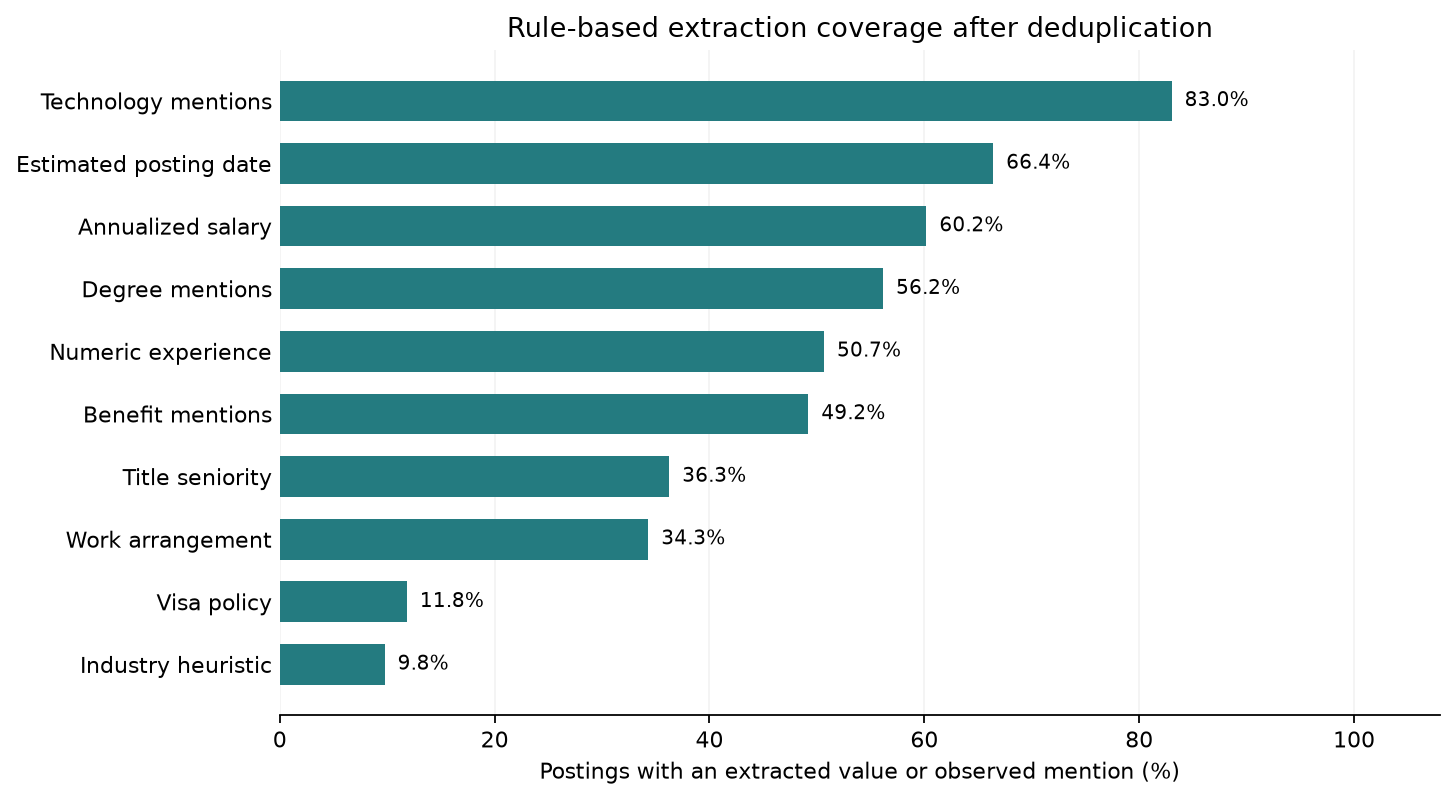

In [5]:
coverage, quality_review = cleaning.quality_tables(cleaned)
coverage.to_csv(REPORTS / "manual-cleaning-coverage.csv", index=False)

valid_salary = cleaned["salary_min"].notna() & cleaned["salary_issue"].isna()
assert cleaned.loc[valid_salary, "salary_min"].le(cleaned.loc[valid_salary, "salary_max"]).all()
known_date = cleaned["posted_date"].notna()
assert cleaned.loc[known_date, "posted_date"].le(cleaned.loc[known_date, "crawl_time_utc"].dt.normalize()).all()
assert all(pd.api.types.is_numeric_dtype(cleaned[column]) for column in cleaning.NUMERIC_COLUMNS)
assert all(pd.api.types.is_datetime64_any_dtype(cleaned[column]) for column in cleaning.DATE_COLUMNS)
assert not cleaned[["job_key", "job_title", "company_name", "description"]].isna().any().any()

core_features = ["job_title", "company_name", "city", "state", "job_type", "salary_annual_mid", "posted_date",
                 "experience_years_min", "experience_level", "education_degrees", "skills", "benefits",
                 "work_arrangement", "visa_sponsorship", "industry", "company_employees", "application_deadline"]
display(coverage.set_index("column").loc[core_features].reset_index())

plot_labels = {
    "salary_annual_mid": "Annualized salary", "posted_date": "Estimated posting date",
    "experience_years_min": "Numeric experience", "experience_level": "Title seniority",
    "education_degrees": "Degree mentions", "skills": "Technology mentions",
    "benefits": "Benefit mentions", "work_arrangement": "Work arrangement",
    "visa_sponsorship": "Visa policy", "industry": "Industry heuristic",
}
plot_data = coverage.set_index("column").loc[list(plot_labels), "coverage_percent"].sort_values()
fig, ax = plt.subplots(figsize=(9.2, 5.1), dpi=160)
ax.barh([plot_labels[c] for c in plot_data.index], plot_data.values, color="#247b80", height=.65)
for y, value in enumerate(plot_data.values):
    ax.text(value+1.2, y, f"{value:.1f}%", va="center", fontsize=9)
ax.set(xlim=(0,108), xlabel="Postings with an extracted value or observed mention (%)",
       title="Rule-based extraction coverage after deduplication")
ax.spines[["top","right","left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=.15)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(REPORTS / "manual-cleaning-coverage.png", dpi=160, bbox_inches="tight")
plt.show()

In [6]:
flag_columns = ["possible_duplicate", "potential_non_job_posting", "salary_multiple_ranges",
                "salary_domain_outlier", "salary_iqr_outlier", "experience_domain_outlier",
                "experience_iqr_outlier", "description_length_outlier", "quality_review"]
display(pd.DataFrame({"flag":flag_columns, "postings_flagged":[int(cleaned[c].sum()) for c in flag_columns]}))
review_columns = ["job_key","job_title","company_name","source_record_count","salary_annual_mid",
                  "salary_source","salary_evidence","salary_issue","salary_multiple_ranges",
                  "work_arrangement","work_arrangement_evidence","experience_years_min"] + flag_columns
review_columns = list(dict.fromkeys(review_columns))
quality_review[review_columns].to_csv(REPORTS / "manual-cleaning-review.csv", index=False)
display(quality_review[review_columns].drop(columns=["salary_evidence","work_arrangement_evidence"]).head(15))

print("Salary unit/currency assumptions among records with parsed salary:")
parsed_salary = cleaned.loc[cleaned["salary_min"].notna()]
display(pd.DataFrame({"assumption":["Annual period inferred", "USD inferred"],
                      "postings":[int(parsed_salary["salary_period_assumed"].sum()),int(parsed_salary["salary_currency_assumed"].sum())]}))

,flag,postings_flagged
0,possible_duplicate,2
1,potential_non_job_posting,2
2,salary_multiple_ranges,21
3,salary_domain_outlier,0
4,salary_iqr_outlier,2
5,experience_domain_outlier,0
6,experience_iqr_outlier,1
7,description_length_outlier,3
8,quality_review,43


,job_key,job_title,company_name,source_record_count,salary_annual_mid,salary_source,salary_issue,salary_multiple_ranges,work_arrangement,experience_years_min,possible_duplicate,potential_non_job_posting,salary_domain_outlier,salary_iqr_outlier,experience_domain_outlier,experience_iqr_outlier,description_length_outlier,quality_review
19,job-aee4f37d7c4743d1ff38,Big Data Engineer III,AAA Northeast,1,151000.0,extensions,<NA>,False,conflicting,6.0,False,False,False,False,False,False,False,True
20,job-6367e32bdc17f595d3b4,Big Data Engineer III (60641),AAA Northeast,1,<NA>,<NA>,<NA>,<NA>,conflicting,6.0,False,False,False,False,False,False,False,True
23,job-ce5a29292e48f5428bef,"Site Strategy Manager, Data Center Sites - Rem...",AECOM,1,185000.0,extensions,<NA>,False,conflicting,8.0,False,False,False,False,False,False,False,True
35,job-0f6a7f67198d8a20aad4,Strategy Data & AI Manager/Senior Manager,Accenture,1,169750.0,benefits_highlight,<NA>,True,<NA>,5.0,False,False,False,False,False,False,False,True
46,job-c9651783e4dccb2b7a17,"Quantitative Analytics Manager, Affirm Bank Mo...",Affirm,1,250000.0,benefits_highlight,<NA>,True,remote,7.0,False,False,False,False,False,False,False,True
47,job-855d84694517fe0ae216,"AVP, Quantitative Risk Analyst","Aflac, Incorporated",1,162500.0,benefits_highlight,<NA>,True,<NA>,5.0,False,False,False,False,False,False,False,True
48,job-d050772012693fe141a8,Statistician & Experimentation Expert,AfterQuery,1,239200.0,description,<NA>,True,remote,<NA>,False,False,False,False,False,False,False,True
54,job-55fa41ba15308691eefe,Statistician - II (Associate),AllSTEM Connections,2,149968.0,benefits_highlight,<NA>,True,<NA>,2.0,False,False,False,False,False,False,False,True
106,job-3c5ac3751fe7742786f7,Principal Machine Learning Systems Engineer - ...,Atlassian,1,272862.5,benefits_highlight,<NA>,True,remote,<NA>,False,False,False,False,False,False,False,True
125,job-d08106a6fbab385cb0ee,Precision Genomics Data Science Co-op,Bayer,1,<NA>,benefits_highlight,period_unknown,False,<NA>,<NA>,False,False,False,False,False,False,False,True


Salary unit/currency assumptions among records with parsed salary:


,assumption,postings
0,Annual period inferred,114
1,USD inferred,322


## 4. Inspect evidence and regression examples from the real crawl

The following fixed sample covers each salary source. The targeted checks reproduce failures found during initial inspection: `401k` is not compensation, work hours do not define the salary period, and commas with spaces remain valid thousands separators. These checks validate parsing against saved text, rather than overriding individual rows.

In [7]:
salary_sample = cleaned.loc[cleaned["salary_min"].notna()].groupby("salary_source",group_keys=False).head(4)
sample_columns = ["job_key","job_title","company_name","salary_min","salary_max","salary_period",
                  "salary_annual_mid","salary_currency_assumed","salary_period_assumed","salary_source","salary_evidence"]
salary_sample[sample_columns].to_csv(REPORTS / "manual-cleaning-evidence-sample.csv",index=False)
with pd.option_context("display.max_colwidth",150):
    display(salary_sample[sample_columns].drop(columns="job_key"))

checks = [
    ("Computational Scientist", "Roswell Park Cancer Institute",129828.0),
    ("Senior Natural Language Processing (NLP) Engineer","Turing Talent",300000.0),
    ("Operations Research Analyst - TS/SCI at System One Kirtland, NM","System One",130000.0),
    ("Quantitative Risk Analyst (Mid-level) - AML Modeling","USAA",136505.0),
    ("AI Solutions Architect — Programs & Delivery","Amentum",170000.0),
]
checked=[]
for title, company, expected in checks:
    row=cleaned.loc[cleaned["job_title"].eq(title) & cleaned["company_name"].eq(company)].iloc[0]
    assert abs(float(row["salary_annual_mid"])-expected)<.01
    checked.append({"job_title":title,"company_name":company,"expected_annual_mid":expected,
                    "parsed_annual_mid":float(row["salary_annual_mid"]),"check":"passed","evidence":row["salary_evidence"]})
pd.DataFrame(checked).to_csv(REPORTS / "manual-cleaning-regression-checks.csv",index=False)
display(pd.DataFrame(checked).drop(columns="evidence"))

,job_title,company_name,salary_min,salary_max,salary_period,salary_annual_mid,salary_currency_assumed,salary_period_assumed,salary_source,salary_evidence
0,Cyber Risk Analyst,"00100 LEIDOS, INC.",57850.0,104575.0,year,81212.5,False,True,benefits_highlight,"Pay Range: Pay Range $57,850.00 - $104,575.00 The Leidos pay range for this job level is a"
2,Distribution ( GIS ) Analytics Manager,0100 KeyBank National Association,96000.0,181000.0,year,138500.0,False,False,description,"tion is eligible to earn a base salary in the range of $96,000.00 - $181,000.00 annually. Placement within the pay range may"
3,Quantitative Credit Data Analyst,0100 KeyBank National Association,71000.0,125000.0,year,98000.0,False,False,benefits_highlight,"tion is eligible to earn a base salary in the range of $71,000.00 - $125,000.00 annually\nPlacement within the pay range may d"
4,"Analyst, Customer Insights",060 SAKS & CO LLC,72000.0,89000.0,year,80500.0,False,True,description,"tact candidatesupport@exemplarluxury.com. Salary Range $72,000 - $89,000* Compensation for this role varies by geogra"
5,Advisor - Computational Statistician,100 Eli Lilly and Company,151500.0,244200.0,year,197850.0,False,True,benefits_highlight,"The anticipated wage for this position is $151,500 - $244,200 Full-time equivalent employees also will be e"
8,"Sr Data Analyst, Ecommerce & Product Analytics (Experimentation, Math/Stats, A/B testing, ML)",1114 Target Enterprise Inc,88000.0,158000.0,year,123000.0,False,True,description,"The pay range is $88,000.00 - $158,000.00 Pay is based on several factors which vary ba"
9,Data Analyst IV,12 Elements Consulting,115000.0,125000.0,year,120000.0,True,False,extensions,115K–125K a year
10,Senior Business Intelligence Analyst,"121 C.H. Robinson Shared Services, Inc.",77000.0,173600.0,year,125300.0,False,True,benefits_highlight,"Compensation Range $77,000.00 - $173,600.00 The base pay range displayed on each job post"
17,Data Scientist Specialist/Bioinformatics Specialist,3M,90000.0,120000.0,year,105000.0,True,False,extensions,90K–120K a year
18,Artificial Intelligence Specialist,631 Booz Allen Hamilton_United States,112800.0,257000.0,year,184900.0,False,True,description,"The projected compensation range for this position is $112,800.00 to $257,000.00 (annualized USD). The estimate displayed repr"


,job_title,company_name,expected_annual_mid,parsed_annual_mid,check
0,Computational Scientist,Roswell Park Cancer Institute,129828.0,129828.0,passed
1,Senior Natural Language Processing (NLP) Engineer,Turing Talent,300000.0,300000.0,passed
2,Operations Research Analyst - TS/SCI at System...,System One,130000.0,130000.0,passed
3,Quantitative Risk Analyst (Mid-level) - AML Mo...,USAA,136505.0,136505.0,passed
4,AI Solutions Architect — Programs & Delivery,Amentum,170000.0,170000.0,passed


## 5. Export and read the CSV back

The requested deliverable is `data/processed-jobs-1.csv`, one row per deduplicated posting. The CSV preserves numeric values and uses blank fields for missing scalars, ISO dates, UTC timestamps, and JSON arrays for multivalued columns. CSV has no native type metadata: the coverage report records the in-memory dtypes, and the explicit read-back checks below validate the serialized values.

| Columns | Interpretation |
|---|---|
| `job_key`, `job_id`, `job_ids` | Stable group key, representative ID, and all original IDs. |
| `source_record_count`, `source_files`, `search_queries` | All occurrences and provenance retained after merging. |
| `alternate_titles`, `locations`, `posting_platforms`, `job_types` | JSON arrays preserving multivalued attributes; `location_raw` is the representative raw location. |
| `salary_min/max/period/currency` | Nominal advertised amounts, not annualized; assumptions are separately flagged. |
| `salary_annual_min/max/mid` | Annualized amounts in the named currency; no currency exchange conversion. |
| `posted_at_raw`, `posted_date`, `posted_date_precision/bound` | Original age token and approximate date/bound anchored to the crawl response. |
| `experience_years_min/max` | Explicit experience range from selected requirement clause; maximum may be missing for `5+ years`. |
| `education_degrees`, `skills`, `certifications`, `benefits`, `soft_skills`, `company_values`, `collaboration_tools`, `required_languages` | Observed mention lists; no mention does not establish absence. |
| `qualifications`, `responsibilities`, `benefits_text`, evidence fields | Structured highlights or matched source excerpts for inspection. |
| `company_employees`, `company_size` | Explicit employee count; size bins: <50 small, 50–249 medium, 250–999 large, ≥1,000 enterprise. |
| `travel_percent_max`, `team_size` | Stated travel percentage maximum and team-size mention, when present. |
| `industry` | Company-name keyword heuristic, with `industry_source` recorded. |
| `application_deadline`, `expected_start_date`, `posting_expiry_date` | Explicit calendar dates with a year only; no invented date for `ASAP`. |
| `*_outlier`, `possible_duplicate`, `salary_multiple_ranges`, `potential_non_job_posting`, `quality_review` | Review indicators; flagged records are retained. |

In [8]:
serialized = cleaning.export_csv(cleaned, OUTPUT)
round_trip = pd.read_csv(OUTPUT, dtype={"job_id":"string", "job_key":"string"})
assert len(round_trip) == len(cleaned)
assert round_trip["job_key"].is_unique
assert round_trip["job_key"].tolist() == cleaned["job_key"].tolist()
for column in cleaning.LIST_COLUMNS:
    assert round_trip[column].map(json.loads).tolist() == cleaned[column].tolist()
for column in cleaning.NUMERIC_COLUMNS:
    actual = pd.to_numeric(round_trip[column], errors="raise")
    expected = cleaned[column].astype("float64")
    assert actual.isna().equals(expected.isna())
    assert (actual-expected).abs().dropna().lt(.0001).all()
for column in cleaning.DATE_COLUMNS:
    actual = pd.to_datetime(round_trip[column], errors="coerce", utc=True)
    assert actual.equals(cleaned[column]), f"Date round-trip failure: {column}"

raw_paths = sorted(DATA.glob("*.json"))
raw_hashes = {str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in raw_paths}
audit = {
    "completion_status":"COMPLETE", "extraction_method":"deterministic Python rules; no LLM/API calls at runtime",
    "raw_response_files":membership["source_file"].nunique(), "raw_records":len(raw_records),
    "output_postings":len(cleaned), "output_columns":len(cleaned.columns),
    "duplicate_occurrences_merged":len(raw_records)-len(cleaned),
    "duplicate_review_pairs_retained":len(duplicate_review),
    "all_raw_occurrences_accounted_for":True, "provided_example_included":False,
    "original_json_sha256":raw_hashes,
    "feature_coverage":{c:round(float(cleaned[c].notna().mean()),4) for c in ["salary_annual_mid","posted_date","experience_years_min","work_arrangement"]},
    "quality_review_postings":int(cleaned["quality_review"].sum()),
    "flags":{c:int(cleaned[c].sum()) for c in flag_columns},
    "unit_tests_passed":int(re.search(r"Ran (\d+) tests", test_run.stderr)[1]), "real_data_salary_regressions_passed":len(checked),
    "csv_round_trip_passed":True, "output_file":str(OUTPUT),
    "output_sha256":hashlib.sha256(OUTPUT.read_bytes()).hexdigest(),
}
(REPORTS / "manual-cleaning-audit.json").write_text(json.dumps(audit,indent=2,default=int)+"\n",encoding="utf-8")
print("Saved:",OUTPUT)
print("Rows:",len(round_trip),"Columns:",len(round_trip.columns))
print("CSV numeric, date, list, row-count, and key checks: passed")
print("Raw-occurrence provenance reconciliation: passed")
print("Part 2 status: COMPLETE")

Saved: data/processed-jobs-1.csv
Rows: 819 Columns: 84
CSV numeric, date, list, row-count, and key checks: passed
Raw-occurrence provenance reconciliation: passed
Part 2 status: COMPLETE


## Findings, limitations, and next step

The extraction deliberately leaves unsupported features missing. Industry and company-size coverage will be limited because these attributes rarely have unambiguous textual evidence. Numeric salary units/currency sometimes require flagged assumptions; multiple regional pay bands remain review cases. Degree and skill lists measure mentions, and regex rules can miss paraphrases or misread complex requirement alternatives.

Exact same-company descriptions across locations are treated as a multi-location posting, with every location retained. A distinct description under the same title/company/location stays in the dataset with a review flag. Very similar but separately requisitioned roles can still be hard to distinguish without an employer's definitive requisition identifier.

Survey-participant advertisements and extreme compensation are kept with flags. Later EDA should report sensitivity to these records, inferred pay units, conflicting work arrangements, and geographic pay bands. This collection is a short-window, search-ranked convenience sample; it cannot establish nationwide hiring trends or seasonality.

After reviewing this part, the student commits and pushes its notebook, HTML, CSV, implementation, tests, and reports. Part 3 will independently extract structured fields with an LLM for comparison. Final submission history is exported after the remaining required parts are complete.

In [9]:
summary = f"""**Actual cleaning result:** {len(raw_records):,} raw occurrences became **{len(cleaned):,} postings** with **{len(cleaned.columns)} columns**. **{len(raw_records)-len(cleaned)} duplicate occurrences** were merged; **{len(duplicate_review)} ambiguous duplicate pair** was retained for review. Annualized salary is available for **{cleaned['salary_annual_mid'].notna().sum():,}** postings and an approximate posting date for **{cleaned['posted_date'].notna().sum():,}**. **{int(cleaned['quality_review'].sum())} postings** carry at least one quality-review flag; none were removed merely for being an outlier."""
display(Markdown(summary))

**Actual cleaning result:** 847 raw occurrences became **819 postings** with **84 columns**. **28 duplicate occurrences** were merged; **1 ambiguous duplicate pair** was retained for review. Annualized salary is available for **493** postings and an approximate posting date for **544**. **43 postings** carry at least one quality-review flag; none were removed merely for being an outlier.

## Implementation appendix

The complete extraction script is included below so the standalone HTML contains the cleaning logic as well as the results. To reproduce locally, run `python run_part2.py`, then `quarto render HW-3.2-cleaning-1.ipynb --no-execute`. Rendering reads saved outputs and performs no cleaning, crawling, or model calls.

In [10]:
display(Code(Path("manual_cleaning.py").read_text(encoding="utf-8"), language="python"))

"""Deterministic cleaning for HW 3.2. No network calls or LLM runtime dependencies."""

from collections import defaultdict
from difflib import SequenceMatcher
import hashlib
import html
import json
from pathlib import Path
import re
import unicodedata

import numpy as np
import pandas as pd


STATES = dict(zip(
    'AL AK AZ AR CA CO CT DE DC FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY'.split(),
    'Alabama|Alaska|Arizona|Arkansas|California|Colorado|Connecticut|Delaware|District of Columbia|Florida|Georgia|Hawaii|Idaho|Illinois|Indiana|Iowa|Kansas|Kentucky|Louisiana|Maine|Maryland|Massachusetts|Michigan|Minnesota|Mississippi|Missouri|Montana|Nebraska|Nevada|New Hampshire|New Jersey|New Mexico|New York|North Carolina|North Dakota|Ohio|Oklahoma|Oregon|Pennsylvania|Rhode Island|South Carolina|South Dakota|Tennessee|Texas|Utah|Vermont|Virginia|Washington|West Virginia|Wisconsin|Wyoming'.split('|')
))
SKILLS = {
    'Python': r'\bpython\b', 'R': r'(?<![\w])R(?!\w|\s*&\s*D)',
    'SQL': r'\bsql\b', 'NoSQL': r'\bnosql\b', 'Java': r'\bjava\b',
    'JavaScript': r'\bjavascript\b', 'C++': r'(?<!\w)c\+\+(?!\w)',
    'C#': r'(?<!\w)c#(?!\w)', 'Scala': r'\bscala\b', 'SAS': r'\bsas\b',
    'MATLAB': r'\bmatlab\b', 'Excel': r'\bexcel\b', 'Tableau': r'\btableau\b',
    'Power BI': r'\bpower\s*bi\b', 'Spark': r'\b(?:apache\s+|py)?spark\b',
    'Hadoop': r'\bhadoop\b', 'Kafka': r'\bkafka\b', 'Airflow': r'\bairflow\b',
    'dbt': r'\bdbt\b', 'Snowflake': r'\bsnowflake\b', 'Databricks': r'\bdatabricks\b',
    'AWS': r'\baws\b|\bamazon web services\b', 'Azure': r'\bazure\b',
    'GCP': r'\bgcp\b|\bgoogle cloud\b', 'Docker': r'\bdocker\b',
    'Kubernetes': r'\bkubernetes\b|\bk8s\b', 'Git': r'\bgit\b|\bgithub\b',
    'TensorFlow': r'\btensorflow\b', 'PyTorch': r'\bpytorch\b',
    'scikit-learn': r'\bscikit[ -]learn\b|\bsklearn\b',
    'Machine learning': r'\bmachine learning\b|\bML\b',
    'Deep learning': r'\bdeep learning\b', 'NLP': r'\bnlp\b|\bnatural language processing\b',
    'Computer vision': r'\bcomputer vision\b',
    'LLM': r'\bllms?\b|\blarge language models?\b',
    'RAG': r'\brag\b|\bretrieval[ -]augmented generation\b',
    'LangChain': r'\blangchain\b', 'LangGraph': r'\blanggraph\b',
    'Statistics': r'\bstatistics\b|\bstatistical\b',
    'A/B testing': r'\ba/b test\w*|\bab testing\b',
    'Optimization': r'\boptimization\b|\boptimisation\b',
    'MLOps': r'\bmlops\b', 'Linux': r'\blinux\b',
}
DEGREES = {
    'High school': r'\bhigh school\b|\bged\b',
    'Associate': r"\bassociate(?:'s)? degree\b",
    'Bachelor': r"\bbachelor(?:'s|s)?\b|\bB\.S\.(?!\w)|\bB\.A\.(?!\w)|\b(?:BS|BA)\s+(?:degree|in\b)",
    'Master': r"\bmaster(?:'s|s)\b|\bmaster (?:degree|of)\b|\bM\.S\.(?!\w)|\bM\.A\.(?!\w)|\b(?:MS|MA)\s+(?:degree|in\b)|\bMBA\b",
    'Doctorate': r'\bph\.?d\.?\b|\bdoctorate\b|\bdoctoral\b',
}
CERTIFICATIONS = {
    'AWS Certified': r'\baws certif\w*', 'PMP': r'\bpmp\b', 'CISSP': r'\bcissp\b',
    'CFA': r'\bcfa\b', 'CPA': r'\bcpa\b', 'Security+': r'\bsecurity\+',
    'Azure certification': r'\bazure.{0,30}certif\w*',
    'Google Cloud certification': r'\bgoogle cloud.{0,30}certif\w*',
    'CompTIA': r'\bcomptia\b', 'Six Sigma': r'\bsix sigma\b',
}
BENEFITS = {
    'Health insurance': r'\bhealth (?:insurance|coverage)\b|\bmedical (?:insurance|coverage)\b',
    'Dental insurance': r'\bdental\b', 'Vision insurance': r'\bvision (?:insurance|coverage|benefits)\b',
    'Paid time off': r'\bpaid time off\b|\bpto\b|\bpaid (?:vacation|leave|holidays)\b',
    'Retirement': r'\b401\s*\(?k\)?|\bretirement (?:plan|benefit|saving)\w*|\bpension\b',
    'Stock/equity': r'\bstock options?\b|\brestricted stock\b|\bequity (?:award|grant|compensation)\w*|\brsus?\b',
    'Bonus': r'\bbonus(?:es)?\b', 'Learning support': r'\btuition (?:reimbursement|assistance)\b|\bprofessional development\b|\blearning (?:budget|stipend)\b',
    'Parental leave': r'\bparental leave\b|\bmat